# EN3160 – Assignment 02: Fitting and Alignment

| | |
|---|---|
| **Index No.** | 230352K |
| **Name** | Kumara K.B.R |
| **GitHub** | https://github.com/buddhi-rash/EN-3160-Assesment-02 |

---

This notebook has the code, results and a short discussion for each question.

- **Q1** – Blob detection with LoG
- **Q2** – Line and circle fitting with RANSAC
- **Q3** – Superimposing an image on a planar surface
- **Q4** – PCB alignment with SIFT and homography

---
# Question 1 — Blob Detection

## Objective
Detect the circular blobs (flower centres) in the sunflower image using the Laplacian of Gaussian (LoG), draw the circles, and report the largest circles and the range of σ used.

## Method
1. Convert the image to grayscale and scale it to [0, 1].
2. For each σ, compute the scale-normalised LoG (σ² × LoG) and stack the responses into a scale space.
3. Keep a point if it is the maximum of its 5×5×5 neighbourhood (scale, y, x) and is above the threshold.
4. Draw a circle at each point with radius r = √2 · σ.

## Parameters
- σ from 4.0 to 25.0 with 30 linearly spaced scales, to cover both the small far flowers and the big near ones.
- Threshold = 0.6 × the maximum response, to ignore weak texture like leaves and shadows.
- 5×5×5 neighbourhood, to avoid duplicate detections of the same blob.
- The image is used at full size (1440 × 1440), so σ is in full-resolution pixels.

## Implementation

Image dimensions: 1440 x 1440


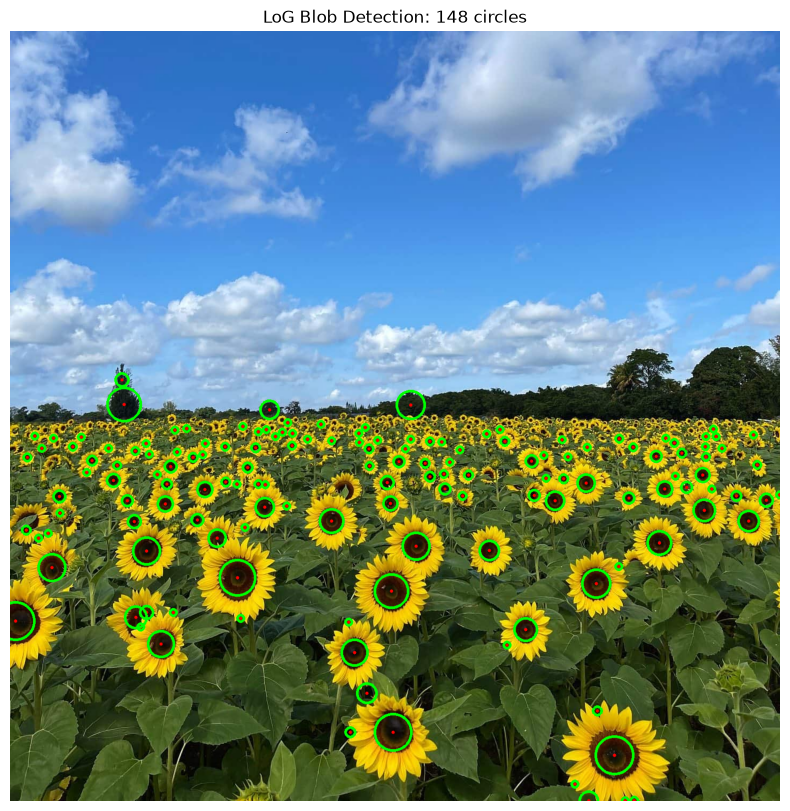

Sigma range used: 4.00 to 25.00 (30 scales)
Largest circles:
  center=(10, 1103), sigma=25.00, radius=35.36
  center=(1130, 1354), sigma=25.00, radius=35.36
  center=(716, 1311), sigma=24.28, radius=34.33
  center=(425, 1022), sigma=23.55, radius=33.31
  center=(213, 698), sigma=22.10, radius=31.26


In [ ]:
# Library import
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
from scipy.ndimage import gaussian_laplace,maximum_filter


# Load the image, convert to grayscale and scale intensities to [0, 1] 
im_1 = cv.imread('images/the_berry_farms_sunflower_field.jpeg')
assert im_1 is not None, "Image not found"
im_1 = cv.cvtColor(im_1, cv.COLOR_BGR2GRAY)
im_1 = im_1.astype(np.float32) / 255.0
print("Image dimensions:", im_1.shape[1], "x", im_1.shape[0])


# Scale-space parameters
min_sigma = 4.0
max_sigma = 25.0
num_sigma = 30

sigmas = np.linspace(min_sigma, max_sigma, num_sigma)
responses = []

# Build the scale space: scale-normalised LoG (sigma^2 * LoG) at every sigma.
# The signed response is kept, so dark blobs (sunflower centres) give POSITIVE values.
for sigma in sigmas:
    response = gaussian_laplace(im_1, sigma=sigma)
    normalized_response = (sigma**2) * (response)
    responses.append(normalized_response)

# Stack the responses into a 3-D volume indexed by (scale, row, column)
scale_space = np.stack(responses, axis=0)
# Keep only strong responses: 60% of the global maximum
threshold = 0.6 * scale_space.max()

# 3-D non-maximum suppression: maximum over each 5x5x5 (scale, y, x) neighbourhood
local_max = maximum_filter(scale_space, size=(5, 5, 5), mode='constant')

# A detection is a local maximum in scale-space that also exceeds the threshold
peaks = ((scale_space == local_max) & (scale_space > threshold))

# Indices of the detected extrema: (scale index, row, column)
sigma_idx, y_coords, x_coords = np.where(peaks)

# Convert every extremum into a circle: centre (x, y) and radius = sqrt(2) * sigma
blobs = []

for si, y, x in zip(sigma_idx, y_coords, x_coords):
    sigma = sigmas[si]
    radius = np.sqrt(2) * sigma

    blobs.append({
        'x': int(x),
        'y': int(y),
        'sigma': float(sigma),
        'radius': float(radius),
        'response': float(scale_space[si, y, x])
    })

# Reload the colour image (converted to RGB) to draw the detected circles on
im_bgr = cv.imread('images/the_berry_farms_sunflower_field.jpeg')
im_rgb = cv.cvtColor(im_bgr, cv.COLOR_BGR2RGB)

# Draw each circle (green outline) and its centre (red dot)
for blob in blobs:
    center = (blob['x'], blob['y'])
    radius = max(1, int(round(blob['radius'])))

    cv.circle(im_rgb, center, radius, (0, 255, 0), 4)
    cv.circle(im_rgb, center, 3, (255, 0, 0), -1)

# Show the detections
plt.figure(figsize=(14, 10))
plt.imshow(im_rgb)
plt.title(f'LoG Blob Detection: {len(blobs)} circles')
plt.axis('off')
plt.show()

# Report the sigma range and the 5 largest circles (required by the task)
print(f"Sigma range used: {sigmas[0]:.2f} to {sigmas[-1]:.2f} ({num_sigma} scales)")
print("Largest circles:")
for b in sorted(blobs, key=lambda b: -b['radius'])[:5]:
    print(f"  center=({b['x']}, {b['y']}), sigma={b['sigma']:.2f}, radius={b['radius']:.2f}")


## Results and Discussion

σ range: 4.0 to 25.0 (30 scales), so the radius goes from about 5.7 px to 35.4 px. Number of detected circles: **148**.

Largest circles:

| Rank | Centre (x, y) | σ | Radius (px) |
|---|---|---|---|
| 1 | (10, 1103) | 25.00 | 35.36 |
| 2 | (1130, 1354) | 25.00 | 35.36 |
| 3 | (716, 1311) | 24.28 | 34.33 |
| 4 | (425, 1022) | 23.55 | 33.31 |
| 5 | (213, 698) | 22.10 | 31.26 |

**Observations**
- The detector finds the dark centres of the sunflowers. The sky and clouds are not detected because they are bright blobs.
- Large circles are at the bottom (flowers close to the camera) and the circles get smaller towards the horizon.
- The top two circles have σ = 25, which is the upper limit of my σ range. Their real size may be bigger, so a larger max σ is needed for them.
- There are a few false detections, for example on the dark trees near the horizon. Some flowers with partly hidden or not-so-dark centres are missed.

---
# Question 2 — Line and Circle Fitting with RANSAC

## Objective
The data has 50 points on a line and 50 points on a circle, both with noise. The steps are:
- (a) fit the line with RANSAC,
- (b) remove the line inliers and fit the circle on the remaining points,
- (c) plot everything,
- (d) discuss what happens if the circle is fitted first.

## Data
The data is generated with the code from the assignment (seed fixed).
- Circle: centre (2, 3), radius 10, radial noise σ = r/16 = 0.625
- Line: y = −x + 2, vertical noise σ = 1

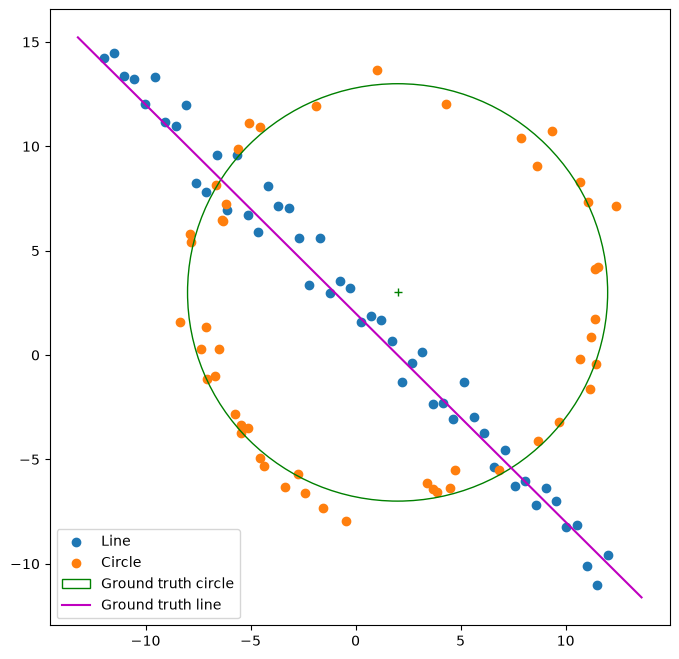

In [ ]:
# Data generation from the listing 1 of the assignment
from scipy.optimize import minimize
from scipy import linalg

np.random.seed(0)
N = 100
half_n = N // 2

r = 10
x0_gt, y0_gt = 2, 3  
s = r / 16

t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)
x, y = x0_gt + (r + n) * np.cos(t), y0_gt + (r + n) * np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

s = 1.0
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

X = np.vstack((X_circ, X_line))  # All points
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.scatter(X_line[:, 0], X_line[:, 1], label="Line")
ax.scatter(X_circ[:, 0], X_circ[:, 1], label="Circle")

circle_gt = plt.Circle(
    (x0_gt, y0_gt), r, color="g", fill=False, label="Ground truth circle"
)
ax.add_patch(circle_gt)
ax.plot((x0_gt), (y0_gt), "+", color="g")

x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m * x_ + b
plt.plot(x_, y_, color="m", label="Ground truth line")
plt.legend()
plt.show()



---
## Part (a) — Line with RANSAC

The line is written as ax + by = d with a unit normal [a, b], so the error of a point is just its distance to the line, |ax + by − d|.

**RANSAC steps**
1. Pick 2 random points and make a line through them.
2. Points with error below the threshold are the inliers (consensus set).
3. Keep the model with the most inliers (it must have at least `min_inliers`).
4. At the end, refit the line on the inliers using total least squares (SVD).

**Parameters**
- Threshold = 1.5. The perpendicular noise is about 0.71, so 1.5 is roughly 2σ.
- Minimum inliers = 40, since there are 50 real line points.
- Iterations = 500, which is more than enough for a 2-point sample.

In [ ]:
# Line through two points -> (a, b, d), with unit normal [a, b] and line equation a*x + b*y = d
def line(p1, p2):
    dx, dy = p2 - p1
    nrm = np.array([-dy, dx])
    L = np.linalg.norm(nrm)
    if L < 1e-12:
        return None
    nrm = nrm / L                       # enforce |[a,b]| = 1
    return nrm[0], nrm[1], nrm @ p1     # a, b, d

# Error of each point = its perpendicular (normal) distance to the line
def line_errors(P, line):
    a, b, d = line
    return np.abs(P[:, 0]*a + P[:, 1]*b - d)   # normal distance

# Total least squares refit: the line passes through the centroid,
def fit_line_tls(P):
    c = P.mean(axis=0)
    _, _, Vt = np.linalg.svd(P - c)
    a, b = Vt[-1]                       # unit normal (smallest singular value)
    return a, b, a*c[0] + b*c[1]

# RANSAC for a line: repeatedly fit a line to 2 random points and keep the model with the largest consensus
def ransac_line(P, thresh, min_inliers, n_iter=500):
    best = None
    for _ in range(n_iter):
        # 1) minimal random sample of 2 points -> candidate line
        idx = np.random.choice(len(P), 2, replace=False)
        model = line(P[idx[0]], P[idx[1]])
        if model is None:
            continue
        # 2) consensus set: points whose normal distance is below the threshold
        err = line_errors(P, model)
        mask = err < thresh
        cnt = mask.sum()
        if cnt < min_inliers:
            continue
        # 3) keep the best model (most inliers; ties broken by the smaller total error)
        score = (cnt, -err[mask].sum())          # more inliers, then lower error
        if best is None or score > best['score']:
            best = dict(score=score, idx=idx, sample_model=model, mask=mask)
    if best is None:
        raise RuntimeError("No consensus found; relax thresh/min_inliers")
    # 4) final TLS refit using all inliers of the best model
    best['refit_model'] = fit_line_tls(P[best['mask']])   # final TLS fit on inliers
    return best

# Threshold 1.5 (~2 sigma of the perpendicular noise); at least 40 of the 100 points must agree
line_res = ransac_line(X, thresh=1.5, min_inliers=40)
a, b_, d = line_res['refit_model']
print(f"Line: normal=({a:.3f},{b_:.3f}), d={d:.3f}, inliers={line_res['mask'].sum()}")
print("Ground truth: normal=±(0.707,0.707), |d|=1.414")

Line: normal=(0.713,0.701), d=1.588, inliers=56
Ground truth: normal=±(0.707,0.707), |d|=1.414


**Result (a)**

| | Estimated | Ground truth |
|---|---|---|
| Unit normal [a, b] | (0.713, 0.701) | (0.707, 0.707) |
| Distance d | 1.588 | 1.414 |
| Inliers | 56 | 50 |

The line is very close to the ground truth. The inlier count is 56, which is more than 50, because the line crosses the circle and a few circle points near the crossings fall inside the threshold strip.

---
## Part (b) — Circle on the remaining points

The line inliers are removed from the data and RANSAC is run again on the rest.

- Sample: 3 random points. The centre is found from the perpendicular bisectors of the chords. Nearly collinear samples are skipped.
- Error: radial error |distance to centre − r|.
- Refit: minimise the sum of squared radial errors on the inliers with `scipy.optimize.minimize` (BFGS).

**Parameters**
- Threshold = 1.5, about 2.4 times the radial noise (0.625).
- Minimum inliers = 40.
- Iterations = 500.

In [83]:
# Circle through 3 points: the centre is the intersection of two perpendicular bisectors (2x2 linear system)
def circle_from_three_points(p1, p2, p3):
    A = 2 * np.array([p2 - p1, p3 - p1])
    rhs = np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1])
    if abs(np.linalg.det(A)) < 1e-9:             # collinear points
        return None
    c = np.linalg.solve(A, rhs)
    return c[0], c[1], np.linalg.norm(p1 - c)

# Radial error: | distance to the centre - radius |
def circle_errors(P, circ):
    cx, cy, rr = circ
    return np.abs(np.hypot(P[:, 0] - cx, P[:, 1] - cy) - rr)

# Refit the circle on the inliers by minimising the sum of squared radial errors with scipy.optimize.minimize
def fit_circle_opt(P, init):
    cost = lambda q: np.sum((np.hypot(P[:, 0]-q[0], P[:, 1]-q[1]) - q[2])**2)
    res = minimize(cost, init, method='BFGS')
    return tuple(res.x)

# RANSAC for a circle: same loop as for the line, but with a 3-point sample and the radial error
def ransac_circle(P, thresh, min_inliers, n_iter=500):
    best = None
    for _ in range(n_iter):
        # 1) minimal random sample of 3 points -> candidate circle
        idx = np.random.choice(len(P), 3, replace=False)
        model = circle_from_three_points(*P[idx])
        if model is None:
            continue
        # 2) consensus set: points whose radial error is below the threshold
        err = circle_errors(P, model)
        mask = err < thresh
        cnt = mask.sum()
        if cnt < min_inliers:
            continue
        # 3) keep the best model (most inliers; ties broken by the smaller total error)
        score = (cnt, -err[mask].sum())
        if best is None or score > best['score']:
            best = dict(score=score, idx=idx, sample_model=model, mask=mask)
    if best is None:
        raise RuntimeError("No consensus found; relax thresh/min_inliers")
    # 4) optimiser refit using all inliers, initialised from the 3-point circle
    best['refit_model'] = fit_circle_opt(P[best['mask']], best['sample_model'])
    return best

# Part (b): remove the line inliers, then run RANSAC for the circle on what remains
# (threshold 1.5 ~ 2.4 x the radial noise; at least 40 points must agree)
# subtract line consensus, fit circle to the remnant
X_rem = X[~line_res['mask']]
circ_res = ransac_circle(X_rem, thresh=1.5, min_inliers=40)
cx, cy, rr = circ_res['refit_model']
print(f"Circle: center=({cx:.3f},{cy:.3f}), r={rr:.3f}, inliers={circ_res['mask'].sum()}")
print("Ground truth: center=(2,3), r=10")

Circle: center=(1.870,3.065), r=9.949, inliers=43
Ground truth: center=(2,3), r=10


**Result (b)**

| | Estimated | Ground truth |
|---|---|---|
| Centre | (1.870, 3.065) | (2, 3) |
| Radius | 9.949 | 10 |
| Inliers | 43 | 50 |

The circle is estimated well even with the line in the data. The inlier count is below 50 because some circle points near the crossings were already taken by the line.

---
## Part (c) — Plot

The plot shows all points, the line and circle inliers, the best samples (2 points for the line, 3 for the circle), the ground truth (green) and the RANSAC result (magenta).

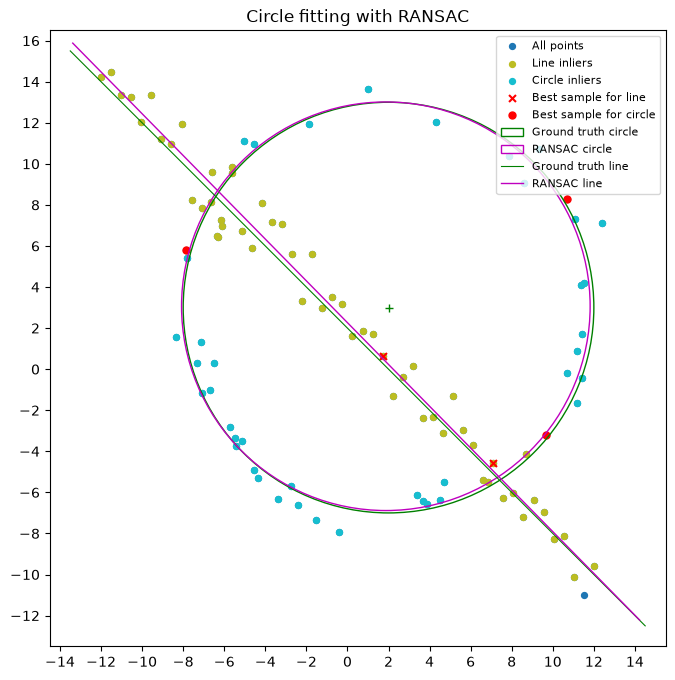

In [85]:
# Part (c): combined plot of the points, the inliers, the best samples, the RANSAC models and the ground truth
fig, ax = plt.subplots(figsize=(8, 8))

# 1. all points (blue), drawn first so the inliers sit on top
ax.scatter(X[:, 0], X[:, 1], s=18, c='tab:blue', label='All points')

# 2. line inliers (olive/yellow)
ax.scatter(X[line_res['mask'], 0], X[line_res['mask'], 1],
           s=18, c='tab:olive', label='Line inliers')

# 3. circle inliers (cyan), taken from the remnant
ax.scatter(X_rem[circ_res['mask'], 0], X_rem[circ_res['mask'], 1],
           s=18, c='tab:cyan', label='Circle inliers')

# 4. best samples (red): x for the line, dots for the circle
ls = X[line_res['idx']]
ax.scatter(ls[:, 0], ls[:, 1], marker='x', s=25, c='red', label='Best sample for line')
cs = X_rem[circ_res['idx']]
ax.scatter(cs[:, 0], cs[:, 1], marker='o', s=25, c='red', label='Best sample for circle')

# 5. ground truth circle (green) and its center
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, fill=False, edgecolor='green',
                        lw=1, label='Ground truth circle'))
ax.plot(x0_gt, y0_gt, '+', color='green')

# 6. RANSAC circle (magenta)
cx, cy, rr = circ_res['refit_model']
ax.add_patch(plt.Circle((cx, cy), rr, fill=False, edgecolor='m',
                        lw=1, label='RANSAC circle'))

# 7. lines: ground truth (green) and RANSAC (magenta)
xs = np.array([-13.5, 14.5])
ax.plot(xs, m*xs + b, color='green', lw=0.8, label='Ground truth line')

a, b_, d = line_res['refit_model']
p0 = d * np.array([a, b_])            # point on the line closest to the origin
dirn = np.array([-b_, a])             # line direction
# Draw the RANSAC line from its parametric form: point on the line + t * direction
tt = np.linspace(-40, 40, 200)
lx, ly = p0[0] + tt*dirn[0], p0[1] + tt*dirn[1]
keep = (lx >= -13.5) & (lx <= 14.5)   # clip to the plot range
ax.plot(lx[keep], ly[keep], color='m', lw=1, label='RANSAC line')

ax.set_xlim(-14.5, 15.5)
ax.set_ylim(-13.5, 16.5)
ax.set_xticks(range(-14, 15, 2))
ax.set_yticks(range(-12, 17, 2))
ax.set_aspect('equal')
ax.legend(loc='upper right', fontsize=8)
ax.set_title('Circle fitting with RANSAC')
plt.show()

**Discussion (c)**
- The RANSAC line and circle almost overlap with the ground truth, so the correct inliers were found.
- Refitting on all inliers is better than using only the minimal sample, because the noise gets averaged over many points instead of 2 or 3.
- The small errors that remain come from the noise and from the crossing points that were given to the wrong model.

---
## Part (d) — What if the circle is fitted first?

It would be less reliable.

1. A circle needs 3 points, and the chance that all 3 are from the circle is about 0.5³ = 1/8. For the line it is 0.5² = 1/4. So the circle needs more iterations.
2. The line points are not random outliers, they form another structure. A circle through three line points has a very large radius and looks like a straight line, so it can collect many line points and win wrongly.
3. The line passes through the circle, so the circle's inlier set would also include some line points near the crossings. This pulls the circle fit away from the true one.
4. Any wrong points removed in the first step also hurt the second step.

So it is better to fit the line first. It is the simpler model (2 points), and after removing its inliers mostly circle points are left.

---
# Question 3 — Superimposing an Image on a Planar Surface

## Objective
Put an image (like a flag) onto a flat surface in another photo. Four corners of the surface are clicked, a homography is computed from them, the overlay is warped and then blended into the photo.

## Method
1. Click 4 corners of the surface in the order top-left, top-right, bottom-right, bottom-left. The corners of the overlay image are used in the same order.
2. Compute the homography H (3×3) from the 4 point pairs. Each pair gives 2 equations, so 4 pairs give 8 equations. H is the right singular vector of the equation matrix with the smallest singular value (DLT). I wrote this by hand and checked it against `cv.getPerspectiveTransform`.
3. Warp the overlay and a white mask with `cv.warpPerspective`. The warped mask gives the area covered by the overlay.
4. Blend inside that area: out = α · warped + (1 − α) · background. With α < 1 the texture of the wall is still visible, so it looks more natural.

## Image pairs

| Pair | Background | Overlay |
|---|---|---|
| 1 | `wadham.jpg` (building) | UK flag |
| 2 | `landscape.jpg` | cropped sunflower field image |
| 3 | `museum.jpg` | Sri Lankan flag |

The target areas are flat and have clear corners, which makes clicking the points easier and gives a better homography. The overlay can also be any image, not only a flag.

## Implementation

In [2]:
%matplotlib qt

In [3]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# Read an image with OpenCV (BGR) and convert it to RGB for Matplotlib
def load_rgb(path):
    im = cv.imread(path)
    assert im is not None, f"Image not found: {path}"
    return cv.cvtColor(im, cv.COLOR_BGR2RGB)

# Interactive selection of the four plane corners (TL, TR, BR, BL) by mouse clicks
def pick_points(im, n=4):
    """Click n points on the image (needs an interactive backend)."""
    plt.figure(figsize=(10, 7))
    plt.imshow(im)
    plt.title("Click TL, TR, BR, BL of the planar surface")
    pts = plt.ginput(n, timeout=0)
    plt.close()
    return np.array(pts, dtype=np.float64)

# Direct Linear Transform (DLT): every correspondence adds two rows to A;
# h is the right singular vector of A with the smallest singular value (H is defined up to scale)
def compute_homography(src, dst):
    """H such that dst ~ H @ src (both Nx2, N>=4), via DLT."""
    A = []
    for (x, y), (u, v) in zip(src, dst):
        A.append([-x, -y, -1,  0,  0,  0, u*x, u*y, u])
        A.append([ 0,  0,  0, -x, -y, -1, v*x, v*y, v])
    A = np.array(A)
    _, _, Vt = np.linalg.svd(A)
    H = Vt[-1].reshape(3, 3)
    return H / H[2, 2]

# Warp the overlay image with H and alpha-blend it into the background
def superimpose(background, flag, dst_pts, alpha=0.6):
    h_f, w_f = flag.shape[:2]
    # Source points: the four corners of the overlay (flag) image, in the same order as the clicks
    src_pts = np.array([[0, 0], [w_f - 1, 0],
                        [w_f - 1, h_f - 1], [0, h_f - 1]], dtype=np.float64)

    # Homography mapping the flag corners to the clicked corners
    H = compute_homography(src_pts, dst_pts)

    # sanity check against OpenCV (should be nearly identical)
    H_check = cv.getPerspectiveTransform(src_pts.astype(np.float32),
                                         dst_pts.astype(np.float32))
    print("H (mine):\n", np.round(H, 4))
    print("max |H - H_opencv/H_opencv[2,2]|:",
          np.abs(H - H_check / H_check[2, 2]).max())

    h_b, w_b = background.shape[:2]
    # Warp the flag, and a white mask of the same size that marks its footprint, into the background frame
    warped = cv.warpPerspective(flag, H, (w_b, h_b))
    mask = cv.warpPerspective(np.ones((h_f, w_f), np.float32), H, (w_b, h_b))
    mask = mask[..., None] * alpha                      # HxWx1, in [0, alpha]

    # Alpha blending inside the footprint only; alpha < 1 keeps the wall texture visible
    out = mask * warped.astype(np.float32) + (1 - mask) * background.astype(np.float32)
    return out.astype(np.uint8)

# Wrapper: load both images, select the points, superimpose and display the result
def run_pair(bg_path, flag_path, pts=None, alpha=0.6, title=""):
    bg = load_rgb(bg_path)
    flag = load_rgb(flag_path)
    if pts is None:
        pts = pick_points(bg)
        print("Clicked points (reuse these to avoid re-clicking):\n", pts.round(1).tolist())
    result = superimpose(bg, flag, pts, alpha)

    fig, ax = plt.subplots(1, 3, figsize=(18, 6))
    ax[0].imshow(bg);   ax[0].plot(*np.vstack([pts, pts[0]]).T, 'r-o'); ax[0].set_title("Clicked plane")
    ax[1].imshow(flag); ax[1].set_title("Flag / overlay image")
    ax[2].imshow(result); ax[2].set_title(title or "Result")
    for a in ax: a.axis('off')
    plt.tight_layout(); plt.show()
    return result

# Pair 1
res1 = run_pair('images/wadham.jpg', 'images/flag.png',
                pts=None,  # or np.array([[x1,y1],[x2,y2],[x3,y3],[x4,y4]])
                alpha=0.6, title="Pair 1: flag on building wall")

# Pair 2
res2 = run_pair('images/landscape.jpg', 'images/the_berry_farms_sunflower_field_cropped.jpeg',
                pts=None, alpha=0.7, title="Pair 2: sunflower field on a landscape")

# Pair 3
res3 = run_pair('images/museum.jpg', 'images/Sl_flag.png',
                pts=None, alpha=0.7, title="Pair 3: sunflower field on a landscape")

# Save the composite images
cv.imwrite('result1.png', cv.cvtColor(res1, cv.COLOR_RGB2BGR))
cv.imwrite('result2.png', cv.cvtColor(res2, cv.COLOR_RGB2BGR))
cv.imwrite('result3.png', cv.cvtColor(res3, cv.COLOR_RGB2BGR))


Clicked points (reuse these to avoid re-clicking):
 [[519.3, 290.2], [148.9, 205.6], [130.8, 550.4], [518.4, 539.0]]
H (mine):
 [[-2.146000e-01 -1.790000e-02  5.193367e+02]
 [-7.380000e-02  2.420000e-01  2.901716e+02]
 [-1.000000e-04 -0.000000e+00  1.000000e+00]]
max |H - H_opencv/H_opencv[2,2]|: 1.37533360202724e-05
Clicked points (reuse these to avoid re-clicking):
 [[609.9, 212.3], [0.3, 210.7], [2.4, 405.0], [609.9, 405.5]]
H (mine):
 [[-4.237000e-01  2.900000e-03  6.099206e+02]
 [-1.900000e-03  2.673000e-01  2.123181e+02]
 [-0.000000e+00  0.000000e+00  1.000000e+00]]
max |H - H_opencv/H_opencv[2,2]|: 9.135584718933387e-06
Clicked points (reuse these to avoid re-clicking):
 [[92.7, 323.2], [724.4, 327.0], [735.5, 672.0], [80.6, 670.2]]
H (mine):
 [[ 1.272000e-01 -4.500000e-03  9.268180e+01]
 [ 1.100000e-03  9.700000e-02  3.232477e+02]
 [ 0.000000e+00 -0.000000e+00  1.000000e+00]]
max |H - H_opencv/H_opencv[2,2]|: 2.0807439682357654e-06


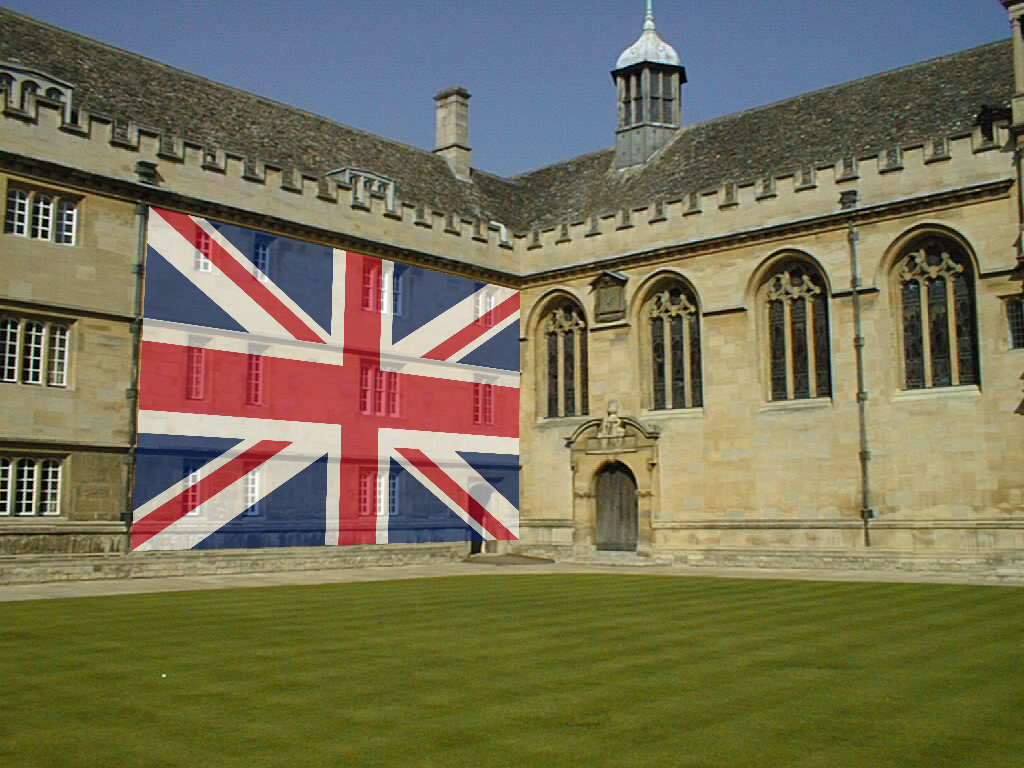

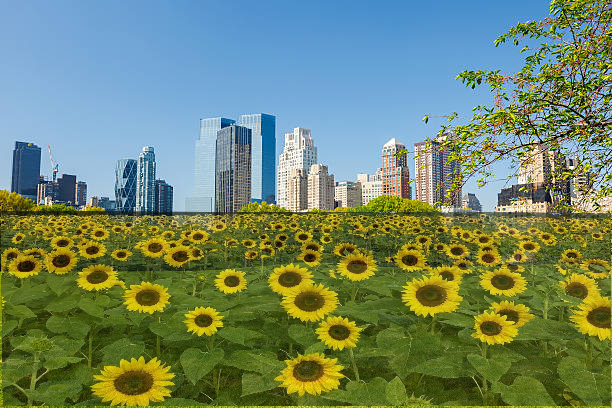

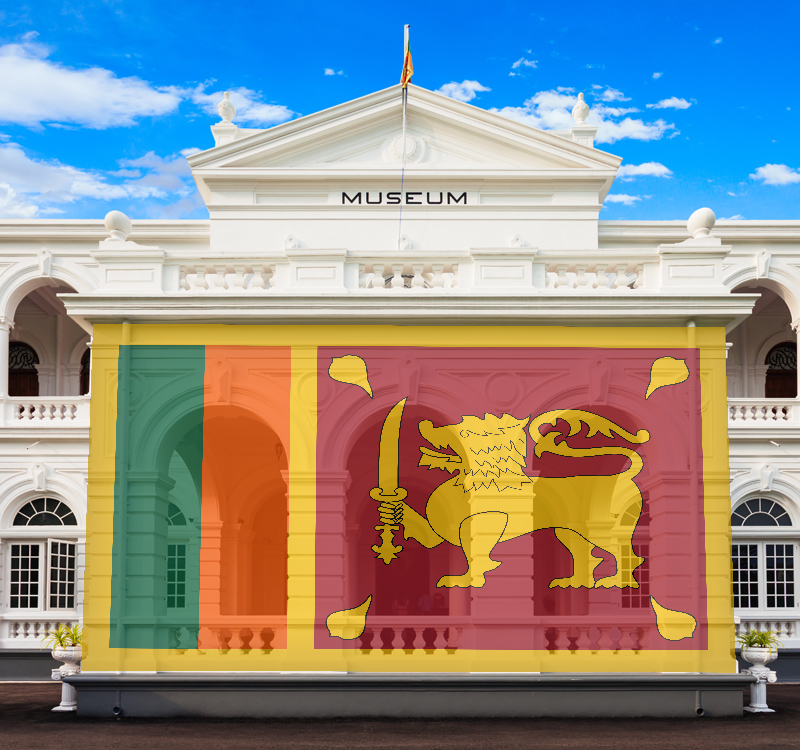

In [4]:
from IPython.display import Image, display

# Display the first result
display(Image(filename='result1.png'))
display(Image(filename='result2.png'))
display(Image(filename='result3.png'))

## Results and Discussion

For pair 1, the clicked points were [[519.3, 290.2], [148.9, 205.6], [130.8, 550.4], [518.4, 539.0]] and my H is

$$H\approx\begin{bmatrix} -0.2146 & -0.0179 & 519.34 \\ -0.0738 & 0.2420 & 290.17 \\ -0.0001 & 0 & 1 \end{bmatrix}$$

The largest difference from the OpenCV result is about 1.4 × 10⁻⁵, which is just rounding error. So the implementation is correct.

**Discussion**
- The overlay follows the perspective of the surface, so it looks attached to the wall.
- Clicking the corners accurately matters most. A few pixels of error can skew the overlay.
- A homography only works for flat surfaces, and this method does not handle objects in front of the wall (occlusions).

---
# Question 4 — PCB Alignment and Difference Image

## Objective
Align each PCB photo with the template (`AECC1.jpg`) and then find the difference between the aligned image and the template.

## Method
The PCB is flat, so two views of it are related by a homography.

1. **(a)** Find SIFT keypoints and descriptors for the template and for each PCB image.
2. **(b)** Match with `BFMatcher` (`knnMatch`, k = 2) and apply Lowe's ratio test (0.75) to remove unclear matches. Then estimate H with `cv2.findHomography` using RANSAC (5 px threshold). Only the inlier matches are drawn.
3. **(c)** Warp the PCB image to the template with `cv2.warpPerspective` and take the absolute difference with the template.
4. **(d)** Run the same steps for all the PCB images.

## Implementation

In [14]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import glob, os

# Load the reference (template) PCB image
template_bgr = cv.imread('images/pcbs/AECC1.jpg')
assert template_bgr is not None, "Template not found"
template_gray = cv.cvtColor(template_bgr, cv.COLOR_BGR2GRAY)

# SIFT detector/descriptor; the template features are computed only once
sift = cv.SIFT_create()
kp_t, des_t = sift.detectAndCompute(template_gray, None)
print("Template keypoints:", len(kp_t))

# Pipeline for one PCB image: SIFT -> matching -> RANSAC homography -> warp -> difference
def align_pcb(pcb_bgr, ratio=0.75, ransac_thresh=5.0):
    pcb_gray = cv.cvtColor(pcb_bgr, cv.COLOR_BGR2GRAY)

    # (a) SIFT features
    kp_p, des_p = sift.detectAndCompute(pcb_gray, None)

    # (b) match with BFMatcher (L2 norm for SIFT) + Lowe's ratio test
    # Brute-force matcher (default L2 norm, suitable for SIFT descriptors)
    bf = cv.BFMatcher()
    knn = bf.knnMatch(des_p, des_t, k=2)         # query = PCB, train = template
    good = [m for m, n in knn if m.distance < ratio * n.distance]
    print(f"  keypoints: {len(kp_p)}, good matches: {len(good)}")
    if len(good) < 4:
        raise RuntimeError("Not enough matches to estimate a homography")

    # Matched coordinates: PCB image (source) -> template (destination)
    src = np.float32([kp_p[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)  # PCB
    dst = np.float32([kp_t[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)  # template
    # Homography estimated with RANSAC (reprojection threshold 5 px); 'mask' flags the inliers
    H, mask = cv.findHomography(src, dst, cv.RANSAC, ransac_thresh)
    inliers = mask.ravel().astype(bool)
    print(f"  RANSAC inliers: {inliers.sum()}/{len(good)}")

    # draw only the RANSAC inlier matches
    match_img = cv.drawMatches(pcb_bgr, kp_p, template_bgr, kp_t, good, None,
                               matchColor=(0, 255, 0),
                               matchesMask=inliers.astype(int).tolist(),
                               flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

    # (c) warp the PCB into the template frame
    h_t, w_t = template_gray.shape
    aligned = cv.warpPerspective(pcb_bgr, H, (w_t, h_t))

    # difference image
    # Absolute per-pixel difference between the template and the aligned PCB
    aligned_gray = cv.cvtColor(aligned, cv.COLOR_BGR2GRAY)
    diff = cv.absdiff(template_gray, aligned_gray)
    return aligned, diff, match_img, H

# 2x2 panel: inlier matches, template, aligned PCB and difference image
def show_result(name, template_bgr, aligned, diff, match_img):
    fig, ax = plt.subplots(2, 2, figsize=(14, 10))
    ax[0, 0].imshow(cv.cvtColor(match_img, cv.COLOR_BGR2RGB)); ax[0, 0].set_title(f"{name}: inlier matches")
    ax[0, 1].imshow(cv.cvtColor(template_bgr, cv.COLOR_BGR2RGB)); ax[0, 1].set_title("Template")
    ax[1, 0].imshow(cv.cvtColor(aligned, cv.COLOR_BGR2RGB)); ax[1, 0].set_title("Aligned PCB")
    ax[1, 1].imshow(diff, cmap='gray'); ax[1, 1].set_title("Difference |template - aligned|")
    for a in ax.ravel(): a.axis('off')
    plt.tight_layout(); plt.show()


# Part (d): run the pipeline on every PCB image and save the results
os.makedirs('output', exist_ok=True)
paths = sorted(p for p in glob.glob('images/pcbs/*.jpg')
               if os.path.basename(p) != 'AECC1.jpg')      # adjust to your folder/names
print("PCB images found:", [os.path.basename(p) for p in paths])

diffs = {}
for p in paths:
    name = os.path.splitext(os.path.basename(p))[0]
    print(name)
    pcb = cv.imread(p)
    aligned, diff, match_img, H = align_pcb(pcb)
    diffs[name] = diff
    show_result(name, template_bgr, aligned, diff, match_img)
    cv.imwrite(f'output/{name}_aligned.png', aligned)
    cv.imwrite(f'output/{name}_diff.png', diff)
    cv.imwrite(f'output/{name}_matches.png', match_img)

# summary figure of all difference images
n = len(diffs)
fig, ax = plt.subplots(1, n, figsize=(5*n, 5), squeeze=False)
for a, (name, d) in zip(ax[0], diffs.items()):
    a.imshow(d, cmap='gray'); a.set_title(name); a.axis('off')
plt.tight_layout(); plt.show()

Template keypoints: 14272
PCB images found: ['AAAA1.jpg', 'ADAD1.jpg', 'AECC2.jpg', 'AECC3.jpg', 'AECC4.jpg']
AAAA1
  keypoints: 2414, good matches: 51
  RANSAC inliers: 18/51
ADAD1
  keypoints: 8486, good matches: 369
  RANSAC inliers: 194/369
AECC2
  keypoints: 12315, good matches: 4322
  RANSAC inliers: 3847/4322
AECC3
  keypoints: 15198, good matches: 5629
  RANSAC inliers: 5006/5629
AECC4
  keypoints: 11610, good matches: 3830
  RANSAC inliers: 3402/3830


## Results (parts b, c, d)

All the output images are in the Outputs folder of the GitHub repo. The template has **14 272** SIFT keypoints.

| PCB image | Keypoints | Good matches | RANSAC inliers | Inlier ratio |
|---|---|---|---|---|
| AAAA1 | 2 414 | 51 | 18 | 35% |
| ADAD1 | 8 486 | 369 | 194 | 53% |
| AECC2 | 12 315 | 4 322 | 3 847 | 89% |
| AECC3 | 15 198 | 5 629 | 5 006 | 89% |
| AECC4 | 11 610 | 3 830 | 3 402 | 89% |

**Discussion**
- AECC2, AECC3 and AECC4 have thousands of matches and about 89% inliers, so the alignment is very good.
- ADAD1 has fewer matches, but 194 inliers is still enough for a good homography.
- AAAA1 is the hardest. It has few keypoints and matches and only 18 inliers, so the alignment is less reliable.
- A high inlier ratio means most matches agree with one transformation, which is what we expect for a flat board.

## Part (e) — Why do the USB port, capacitors and reset button show a high difference?

The homography only aligns the flat surface of the board. These parts are different because:

1. They stand above the board, so they are not on the same plane. When the camera position changes, they shift differently (parallax), and the warp cannot fix this.
2. They are shiny and metallic, so their brightness changes with the light and camera angle.
3. They cast shadows, and the shadows move when the lighting or camera changes.
4. They have sharp edges, so even a small alignment error shows up as a strong difference there.

Taking the photos from straight above with even lighting would reduce these differences.

---
# Summary and Conclusions

- **Q1** – LoG blob detection with σ from 4 to 25 found the dark flower centres (148 circles). The biggest circles are on the flowers nearest to the camera.
- **Q2** – RANSAC with a 2-point sample for the line and a 3-point sample for the circle, followed by a refit on the inliers, gave results close to the ground truth. Fitting the line first works better.
- **Q3** – A homography from 4 clicked corners (checked against OpenCV) with alpha blending places an image on a flat surface.
- **Q4** – SIFT, ratio test and RANSAC homography aligned the PCB images with the template. AECC2–4 aligned very well, AAAA1 and ADAD1 were harder. Tall and shiny components still show differences.

In all four questions the main idea was robust model fitting: pick a suitable model, use RANSAC to separate inliers from outliers, and refine the model on the inliers.